# Преобразование Зака: математика с нуля и нуль в точке (½, ½)

В `zak_sim` преобразование Зака — готовый инструмент: взяли DZT, построили пульсон, посчитали канал. Здесь мы его **выводим**: что это за операция, откуда берётся «странная» квазипериодичность, почему оно ничего не теряет, и главное — **почему у преобразования Зака любого гладкого, хорошо локализованного импульса обязательно есть нуль, а у симметричного импульса он сидит ровно в точке $(\tfrac12,\tfrac12)$ единичной ячейки**. Из этого нуля вырастает теорема Балиана–Лоу и ответ на вопрос «почему гауссовы символы в Zak-OTFS не ортогональны» (разделы 1 и 5 `zak_sim`).

Нужно знать только ряды Фурье. План:
1. **Идея**: порезать ленту сигнала на куски и сделать БПФ поперёк кусков (дискретный случай, считается в одну строку).
2. **Определение** в непрерывном виде и смысл переменных $(\tau,\nu)$.
3. **Квазипериодичность**: два вывода в две строки; откуда берётся скрутка $e^{j2\pi\nu\tau}$.
4. **Обратное преобразование и равенство Парсеваля** — Зак ничего не теряет и не дублирует.
5. **Связь с Фурье** (формула Пуассона): Зак — «середина» между временем и частотой.
6. **Атлас примеров**: δ-импульс, синусоида, прямоугольник, гауссиан.
7. **Нуль в $(\tfrac12,\tfrac12)$**: три объяснения (знакопеременная сумма, симметрия + скрутка, топология), как нуль двигается и что он «вихрь».
8. **Следствия**: ортонормальность решётки импульсов $\Leftrightarrow$ $\lvert Z\rvert\equiv1$, матрица Грама, теорема Балиана–Лоу, цена ортогонализации.
9. **Дискретный вариант**: почему сетка $M\times N$ с чётными $M,N$ попадает в нуль точно.

**Соглашение.** В математических разделах берём $\tau_p=\nu_p=1$ (время измеряется в периодах $\tau_p$, доплер — в $\nu_p=1/\tau_p$), как и в `zak_sim`; нормировочный множитель $\sqrt{\tau_p}$ там превращается в 1. Каждое утверждение проверяется численно: теория печатается рядом с измеренным.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import hsv_to_rgb
from scipy.optimize import minimize

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(1)

K_SUM = 40            # суммируем k = −K…K; хвосты гауссианов e^{−πk²} дальше ≈ 0

## Примитивы: преобразование Зака (по времени и по спектру), сигналы, раскраска «фаза + модуль»

In [2]:
# ---------- непрерывное преобразование Зака (τp = νp = 1) ----------
def zak(x, tau, nu, K=K_SUM):
    """Z(τ,ν) = Σ_{k=−K..K} x(τ+k)·e^{−j2πνk} на сетке τ × ν (tau, nu — одномерные массивы); x — функция времени"""
    k = np.arange(-K, K + 1)
    xs = x(np.asarray(tau, float)[:, None] + k)                  # (Nτ, 2K+1): гребёнка отсчётов для каждого τ
    return xs @ np.exp(-2j * np.pi * np.outer(k, np.atleast_1d(nu)))

def zak_pairs(x, tau, nu, K=K_SUM):
    """то же, но по парам точек (τ_i, ν_i) — для путей и отдельных точек"""
    k = np.arange(-K, K + 1)
    tau = np.atleast_1d(np.asarray(tau, float)); nu = np.atleast_1d(np.asarray(nu, float))
    return (x(tau[:, None] + k) * np.exp(-2j * np.pi * nu[:, None] * k)).sum(1)

def zak_from_spectrum(X, tau, nu, K=K_SUM):
    """Z(τ,ν) = e^{j2πντ}·Σ_m X(ν+m)·e^{j2πmτ}: то же преобразование, но через спектр X(f) сигнала"""
    m = np.arange(-K, K + 1)
    tau = np.asarray(tau, float); nu = np.atleast_1d(np.asarray(nu, float))
    return np.exp(2j * np.pi * np.outer(tau, nu)) * (X(nu[:, None] + m) @ np.exp(2j * np.pi * np.outer(m, tau))).T

# ---------- сигналы ----------
def gauss(t, a=1.0):  return np.exp(-np.pi * (t / a) ** 2)          # при a = 1 гауссиан равен своему же спектру
def rect(t):          return ((t >= 0) & (t < 1)).astype(float)       # прямоугольник на [0,1)
def sinc_t(t):        return np.sinc(t)                                # sin(πt)/(πt)

def random_signal(rng, n=5):
    """гладкий сигнал общего вида: сумма сдвинутых и промодулированных гауссианов"""
    c = rng.uniform(-1, 1, n); w = rng.uniform(0.6, 1.2, n); f = rng.uniform(-1, 1, n)
    amp = rng.standard_normal(n) + 1j * rng.standard_normal(n)
    return lambda t: sum(amp[i] * gauss(np.asarray(t) - c[i], w[i]) * np.exp(2j * np.pi * f[i] * np.asarray(t)) for i in range(n))

def phase_rgb(Z, vmax=None):
    """цвет = фаза, яркость = модуль"""
    A = np.abs(Z); vmax = vmax or A.max()
    h = (np.angle(Z) / (2 * np.pi)) % 1
    return hsv_to_rgb(np.stack([h, np.ones_like(h), np.clip(A / vmax, 0, 1)], -1))

def show_dd(ax, Z, ext, title, vmax=None, phase=False):
    """Z[iτ, iν] → картинка с осью τ по горизонтали, ν по вертикали"""
    img = phase_rgb(Z.T, vmax) if phase else np.abs(Z.T)
    im = ax.imshow(img, origin="lower", extent=ext, aspect="equal", cmap=None if phase else "viridis", vmin=0 if not phase else None)
    ax.set_xlabel("τ / τp"); ax.set_ylabel("ν / νp"); ax.set_title(title, fontsize=10); ax.grid(False)
    return im

## 1. Идея: лента, нарезанная на полоски
Возьмём сигнал из $MN$ отсчётов, **разрежем на $N$ блоков по $M$ отсчётов** и положим блоки друг под другом: получится матрица $A[n,k]=x[k+nM]$, где $k=0\dots M-1$ — позиция внутри блока («быстрое время», задержка), $n=0\dots N-1$ — номер блока («медленное время»). Теперь сделаем **БПФ вдоль $n$ в каждом столбце**:
$$Z[k,l]=\frac1{\sqrt N}\sum_{n=0}^{N-1}x[k+nM]\,e^{-j2\pi nl/N}.$$
Это и есть дискретное преобразование Зака (DZT). Больше в нём ничего нет: **reshape + БПФ**.

Почему $k$ — задержка, а $l$ — доплер. Задержка сигнала на $d$ отсчётов сдвигает картинку по $k$. Доплер $\nu$ умножает сигнал на $e^{j2\pi\nu t}$; в соседних блоках (отстоящих на $\tau_p=M/B$) одна и та же позиция $k$ получает множитель $e^{j2\pi\nu\tau_p}$, то есть вдоль $n$ сигнал вращается с частотой $\nu\tau_p$ — а это ровно то, что находит БПФ по $n$: пик в $l=N\nu/\nu_p$. Поэтому двумерная картинка $Z[k,l]$ — это «где в периоде» × «как быстро это место меняется от периода к периоду».

Ниже: лента из 12 отсчётов, $M=4$, $N=3$. БПФ совпадает с суммой «в лоб» до машинной точности.

лента x  = [3 1 4 1 5 9 2 6 5 3 5 8]
после reshape (строка = блок, столбец = задержка k):
 [[3 1 4 1]
 [5 9 2 6]
 [5 3 5 8]]
max |БПФ − определение| = 4.0e-15


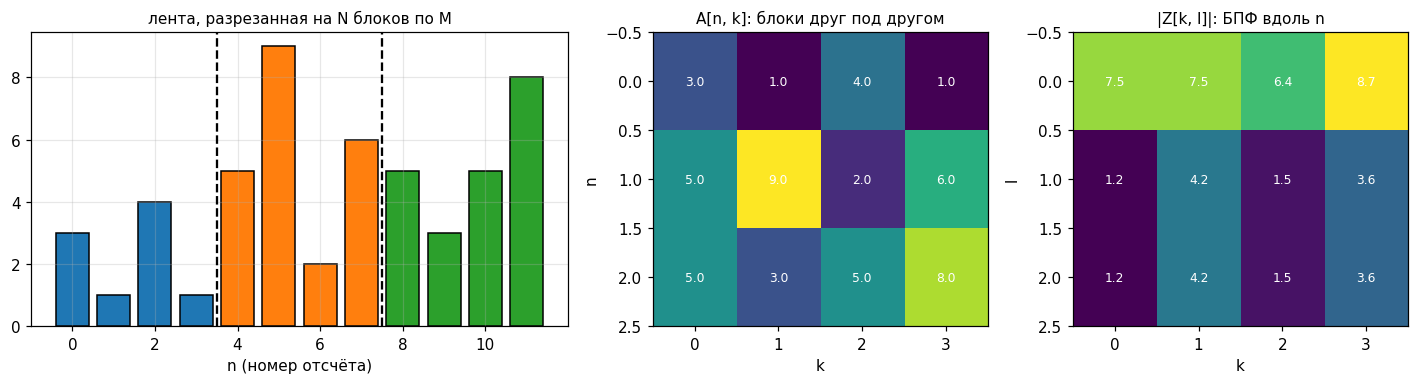

In [3]:
M, N = 4, 3                                       # 4 отсчёта задержки в блоке × 3 блока
x = np.array([3, 1, 4, 1, 5, 9, 2, 6, 5, 3, 5, 8], complex)    # лента из MN = 12 отсчётов
A = x.reshape(N, M)                               # строка n — блок n: A[n, k] = x[k + nM]
Z_fft = (np.fft.fft(A, axis=0) / np.sqrt(N)).T    # Z[k, l]: БПФ по номеру блока n
Z_sum = np.array([[sum(x[k + n * M] * np.exp(-2j * np.pi * n * l / N) for n in range(N)) / np.sqrt(N)
                   for l in range(N)] for k in range(M)])        # определение в лоб
print("лента x  =", x.real.astype(int))
print("после reshape (строка = блок, столбец = задержка k):\n", A.real.astype(int))
print(f"max |БПФ − определение| = {np.max(np.abs(Z_fft - Z_sum)):.1e}")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1.6, 1, 1]})
ax[0].bar(np.arange(M * N), x.real, color=[f"C{i // M}" for i in range(M * N)], edgecolor="k")
for n in range(1, N): ax[0].axvline(n * M - 0.5, color="k", ls="--")
ax[0].set_xlabel("n (номер отсчёта)"); ax[0].set_title("лента, разрезанная на N блоков по M", fontsize=10)
for a, img, ttl in ((ax[1], A.real, "A[n, k]: блоки друг под другом"), (ax[2], np.abs(Z_fft.T), "|Z[k, l]|: БПФ вдоль n")):
    a.imshow(img, cmap="viridis", aspect="auto"); a.grid(False); a.set_title(ttl, fontsize=10)
    for (i, j), v in np.ndenumerate(img): a.text(j, i, f"{v:.1f}", ha="center", va="center", color="w", fontsize=8)
ax[1].set_xlabel("k"); ax[1].set_ylabel("n"); ax[2].set_xlabel("k"); ax[2].set_ylabel("l")
plt.tight_layout(); plt.show()

## 2. Непрерывное определение
Пусть $x(t)$ — сигнал на всей оси, а период $\tau_p=1$. Зафиксируем **сдвиг внутри периода** $\tau$ и возьмём «гребёнку» отсчётов $\{x(\tau+k)\}_{k\in\mathbb Z}$ — значения сигнала в точках $\tau,\ \tau\pm1,\ \tau\pm2,\dots$. Это последовательность по $k$; её ряд Фурье по «частоте» $\nu$ и есть преобразование Зака:
$$\boxed{\,Z_x(\tau,\nu)=\sum_{k\in\mathbb Z}x(\tau+k)\,e^{-j2\pi\nu k}\,}$$
Читать так: **$\tau$ — «в каком месте периода мы смотрим»; $\nu$ — «с какой скоростью меняется значение в этом месте от периода к периоду»**. Два экстремальных примера: если $x$ — δ-импульс, то при любом $\nu$ гребёнка либо пуста, либо одна точка, и $\lvert Z\rvert$ не зависит от $\nu$; если $x=e^{j2\pi f t}$ — чистая синусоида, то от периода к периоду значение просто умножается на $e^{j2\pi f}$, и вся энергия сидит на одном $\nu=f \bmod 1$.

Слева: гауссиан и две гребёнки (для $\tau=0.2$ и $\tau=0.5$). Справа: $\lvert Z(\tau,\nu)\rvert$ как функция $\nu$ для этих двух $\tau$. Обратите внимание на красную кривую ($\tau=0.5$): она касается нуля при $\nu=0.5$. Это и есть нуль, ради которого написан ноутбук.

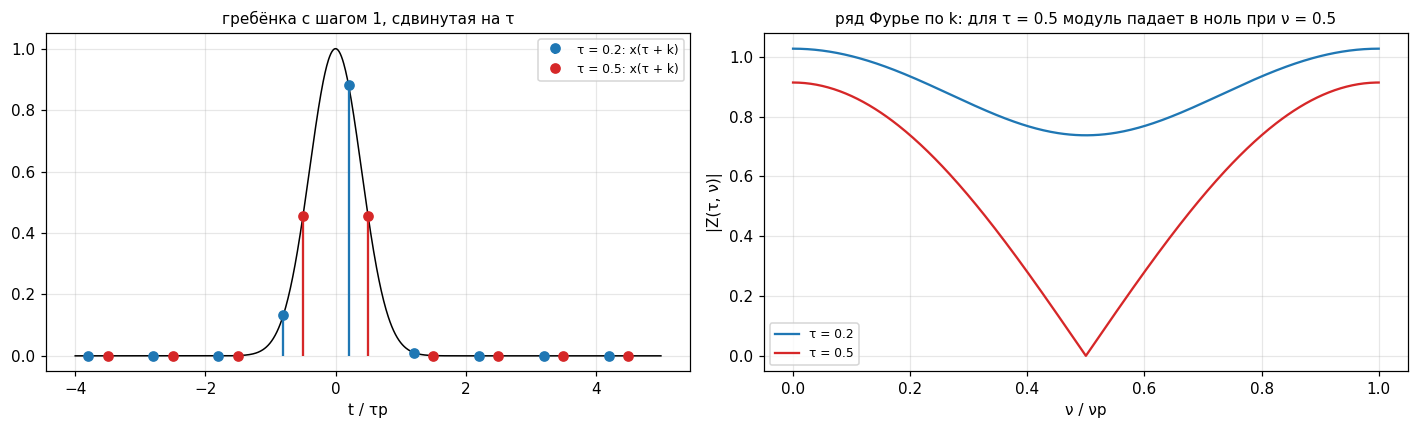

|Z(0.2, 0.5)| = 0.7372      |Z(0.5, 0.5)| = 5.55e-17


In [4]:
g = gauss
t = np.linspace(-4, 5, 1000)
nu = np.linspace(0, 1, 401)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(t, g(t), "k", lw=1)
for tau0, c in ((0.2, "C0"), (0.5, "C3")):
    ks = np.arange(-4, 5)
    ax[0].stem(tau0 + ks, g(tau0 + ks), linefmt=c + "-", markerfmt=c + "o", basefmt=" ", label=f"τ = {tau0}: x(τ + k)")
    ax[1].plot(nu, np.abs(zak(g, [tau0], nu)[0]), c, label=f"τ = {tau0}")
ax[0].set_xlabel("t / τp"); ax[0].legend(fontsize=8); ax[0].set_title("гребёнка с шагом 1, сдвинутая на τ", fontsize=10)
ax[1].set_xlabel("ν / νp"); ax[1].set_ylabel("|Z(τ, ν)|"); ax[1].legend(fontsize=8)
ax[1].set_title("ряд Фурье по k: для τ = 0.5 модуль падает в ноль при ν = 0.5", fontsize=10)
plt.tight_layout(); plt.show()
print(f"|Z(0.2, 0.5)| = {abs(zak_pairs(g, 0.2, 0.5)[0]):.4f}      |Z(0.5, 0.5)| = {abs(zak_pairs(g, 0.5, 0.5)[0]):.2e}")

## 3. Квазипериодичность: откуда скрутка
**По $\nu$.** $e^{-j2\pi(\nu+1)k}=e^{-j2\pi\nu k}$ для целых $k$, значит $Z(\tau,\nu+1)=Z(\tau,\nu)$: чистый период 1.

**По $\tau$.** Сдвинем $\tau$ на 1 и переобозначим $m=k+1$:
$$Z(\tau+1,\nu)=\sum_k x(\tau+k+1)e^{-j2\pi\nu k}=\sum_m x(\tau+m)\,e^{-j2\pi\nu(m-1)}=e^{\,j2\pi\nu}\,Z(\tau,\nu).$$
Сдвиг на период по задержке не возвращает функцию, а **умножает на фазу, зависящую от $\nu$**. В общем виде
$$\boxed{Z(\tau+n,\nu+m)=e^{\,j2\pi n\nu}\,Z(\tau,\nu)\qquad n,m\in\mathbb Z}$$
Это и есть «квазипериодичность» из `zak_sim`. Её следствия:
- **модуль $\lvert Z\rvert$ периодичен по обеим осям**, а вся фазовая «непериодичность» собрана в множителе $e^{j2\pi n\nu}$;
- достаточно знать $Z$ на **единичном квадрате** $[0,1)^2$ — остальная плоскость восстанавливается;
- фаза «закручена»: при сдвиге $\tau$ на 1 значение умножается на $e^{j2\pi\nu}$: при $\nu=\tfrac12$ это $-1$ (пол-оборота), при $\nu=1$ — полный оборот. Это не случайность, а та же некоммутативность задержки и доплера, из-за которой в канале появляется скрученная свёртка: $T_\tau D_\nu=e^{-j2\pi\nu\tau}D_\nu T_\tau$.

Ниже проверка на сигнале общего вида (комплексном, несимметричном) в 2000 случайных точках, и картинка гауссиана на девяти ячейках: слева модуль (повторяется), справа фаза (цвет закручивается вдоль $\tau$).

max|Z(τ+1,ν) − e^(j2πν)·Z(τ,ν)| = 7.7e-15      max|Z(τ,ν+1) − Z(τ,ν)| = 1.4e-14      max|Z(τ−3,ν) − e^(−j2π·3ν)·Z(τ,ν)| = 2.4e-14


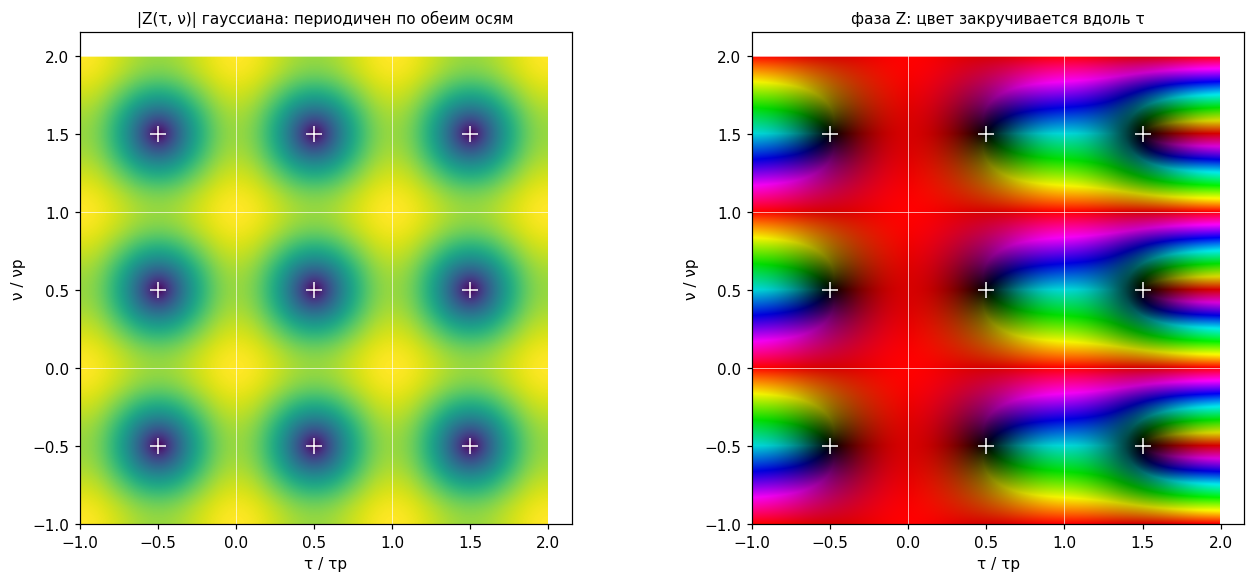

In [5]:
xr = random_signal(rng)                                         # сигнал общего вида (не чётный, не вещественный)
P = rng.uniform(-2, 2, (2000, 2)); tt, nn = P[:, 0], P[:, 1]
Z0 = zak_pairs(xr, tt, nn)
e_tau = np.max(np.abs(zak_pairs(xr, tt + 1, nn) - np.exp(2j * np.pi * nn) * Z0))
e_nu = np.max(np.abs(zak_pairs(xr, tt, nn + 1) - Z0))
e_tau3 = np.max(np.abs(zak_pairs(xr, tt - 3, nn) - np.exp(-2j * np.pi * 3 * nn) * Z0))
print(f"max|Z(τ+1,ν) − e^(j2πν)·Z(τ,ν)| = {e_tau:.1e}      max|Z(τ,ν+1) − Z(τ,ν)| = {e_nu:.1e}      max|Z(τ−3,ν) − e^(−j2π·3ν)·Z(τ,ν)| = {e_tau3:.1e}")

tau = np.arange(-150, 300) / 150; nu = np.arange(-150, 300) / 150
Zg = zak(g, tau, nu)
fig, ax = plt.subplots(1, 2, figsize=(12.5, 5.4))
ext = (tau[0], tau[-1], nu[0], nu[-1])
show_dd(ax[0], Zg, ext, "|Z(τ, ν)| гауссиана: периодичен по обеим осям")
show_dd(ax[1], Zg, ext, "фаза Z: цвет закручивается вдоль τ", phase=True)
for a in ax:
    for u in range(-1, 3): a.axvline(u, color="w", lw=0.6, alpha=0.7); a.axhline(u, color="w", lw=0.6, alpha=0.7)
    a.plot([0.5 + i for i in range(-1, 2)] * 3, [0.5 + j for j in range(-1, 2) for _ in range(3)], "w+", ms=10)
plt.tight_layout(); plt.show()

## 4. Обратное преобразование и равенство Парсеваля
Раз $Z(\tau,\cdot)$ — ряд Фурье последовательности $x(\tau+k)$, то коэффициенты берутся интегралом по периоду $\nu\in[0,1)$. Для $k=0$:
$$\boxed{x(t)=\int_0^1 Z(t,\nu)\,d\nu}\qquad\text{(потому что }\textstyle\int_0^1e^{-j2\pi\nu k}d\nu=\delta_{k0}).$$
А энергия: разобьём ось на ячейки $[n,n+1)$, потом применим равенство Парсеваля для рядов Фурье при каждом $\tau$:
$$\int_{-\infty}^{\infty}\lvert x(t)\rvert^2dt=\int_0^1\sum_k\lvert x(\tau+k)\rvert^2d\tau=\int_0^1\!\!\int_0^1\lvert Z(\tau,\nu)\rvert^2\,d\nu\,d\tau.$$
Итог: **$x\mapsto Z_x$ — унитарное отображение** $L^2(\mathbb R)\to L^2([0,1)^2)$. Информация не теряется (обратное есть) и не дублируется (энергия сохраняется). Именно поэтому «Зак-плоскость» — честная замена оси времени, а не ещё одно избыточное представление вроде спектрограммы.

In [6]:
nu_g = np.arange(64) / 64
t0 = rng.uniform(-3, 3, 6)
x_rec = zak(xr, t0, nu_g).mean(axis=1)                          # ∫₀¹ Z(t, ν) dν
print(f"восстановление x(t) = ∫₀¹ Z(t,ν)dν, шесть случайных t: max|ошибка| = {np.max(np.abs(x_rec - xr(t0))):.1e}")

dt = 0.005; tg = np.arange(-15, 15, dt)
E_time = np.sum(np.abs(xr(tg)) ** 2) * dt                       # ∫|x(t)|² dt
Zq = zak(xr, np.arange(200) / 200, np.arange(64) / 64)
E_zak = np.mean(np.abs(Zq) ** 2)                                # ∬ over the unit cell
print(f"∫|x|²dt = {E_time:.6f}      ∬_[0,1)² |Z|² dτdν = {E_zak:.6f}      отн. разница = {abs(E_time - E_zak) / E_time:.1e}")

восстановление x(t) = ∫₀¹ Z(t,ν)dν, шесть случайных t: max|ошибка| = 1.6e-16
∫|x|²dt = 3.609163      ∬_[0,1)² |Z|² dτdν = 3.609163      отн. разница = 1.6e-13


## 5. Связь с Фурье: Зак — «середина» между временем и частотой
Применим к сумме по $k$ формулу Пуассона $\sum_k f(k)=\sum_m\hat f(m)$ с $f(s)=x(\tau+s)e^{-j2\pi\nu s}$. Преобразование Фурье такой $f$ равно $e^{j2\pi(\nu+m)\tau}X(\nu+m)$, поэтому
$$\boxed{Z_x(\tau,\nu)=e^{\,j2\pi\nu\tau}\sum_{m\in\mathbb Z}X(\nu+m)\,e^{\,j2\pi m\tau}}$$
Это **то же самое преобразование, но посчитанное по отсчётам спектра** $X(f)$ в точках $\nu,\ \nu\pm1,\dots$ (гребёнка в частоте). Роли симметричны: гребёнка по времени + ряд Фурье по $\nu$ $\Leftrightarrow$ гребёнка по частоте + ряд Фурье по $\tau$. Поэтому плоскость $(\tau,\nu)$ не «ближе ко времени» и не «ближе к частоте»: это общий промежуточный язык, на котором и сигнал, и его спектр выглядят одинаково. Практически важно ещё одно: для фильтра, у которого локализован спектр, а не импульс (sinc), формулу можно использовать напрямую.

Проверка на гауссиане ширины $a=0.7$, $X(f)=a\,e^{-\pi a^2f^2}$.

In [7]:
a = 0.7
ga  = lambda t: gauss(t, a)
Ga  = lambda f: a * np.exp(-np.pi * (a * f) ** 2)                # преобразование Фурье гауссиана
tt = rng.uniform(-1, 1, 5); nn = rng.uniform(-1, 1, 5)
Z_time = zak_pairs(ga, tt, nn)
Z_freq = np.array([zak_from_spectrum(Ga, [u], [v])[0, 0] for u, v in zip(tt, nn)])
print("Z по отсчётам времени :", np.round(Z_time, 6))
print("Z по отсчётам спектра:", np.round(Z_freq, 6))
print(f"max|Δ| = {np.max(np.abs(Z_time - Z_freq)):.1e}")

Z по отсчётам времени : [-0.232789-2.38254e-01j  0.862148-1.16778e-01j  1.000241+5.04000e-04j
  0.753863-5.21082e-01j -0.437814-2.59442e-01j]
Z по отсчётам спектра: [-0.232789-2.38254e-01j  0.862148-1.16778e-01j  1.000241+5.04000e-04j
  0.753863-5.21082e-01j -0.437814-2.59442e-01j]
max|Δ| = 2.5e-16


## 6. Атлас примеров
Посмотрим на $\lvert Z\rvert$ на единичном квадрате для четырёх сигналов:
- **почти δ-импульс** (узкий гауссиан): энергия в узкой полосе по $\tau$ вдоль всех $\nu$ — локализован по задержке, размазан по доплеру;
- **почти синусоида** (очень широкий гауссиан): наоборот, узкая полоса по $\nu$ вдоль всех $\tau$;
- **гауссиан $a=1$**: локализован в обеих осях — «пятно»; с $a=1$ он совпадает со своим спектром, и картинка симметрична по $\tau\leftrightarrow\nu$;
- **прямоугольник $[0,1)$**: на $[0,1)$ в гребёнку попадает ровно один отсчёт ($k=0$), поэтому $Z\equiv1$ и $\lvert Z\rvert\equiv1$ **везде**, без всякого нуля. Но это *разрывный* $Z$: на границе $\tau=1$ он «перепрыгивает» $1\to e^{j2\pi\nu}$. (На картинках δ-импульс лежит при $\tau=0\equiv1$, поэтому полосы у левого и правого краёв.)

Таблица под картинкой — минимум и максимум $\lvert Z\rvert$. У всех гладких сигналов минимум — нуль (до машинной точности, потому что сетка содержит точку $(0.5,0.5)$); у прямоугольника — единица. Мы вернёмся к этому контрасту в разделах 7–8.

сигнал                                          min|Z|    max|Z|
почти δ-импульс (a = 0.08)                    6.20e-70  1.00e+00
гауссиан a = 1                                6.01e-17  1.09e+00
прямоугольник [0,1)                           1.00e+00  1.00e+00
почти синусоида (a = 12)                      5.36e-18  1.20e+01


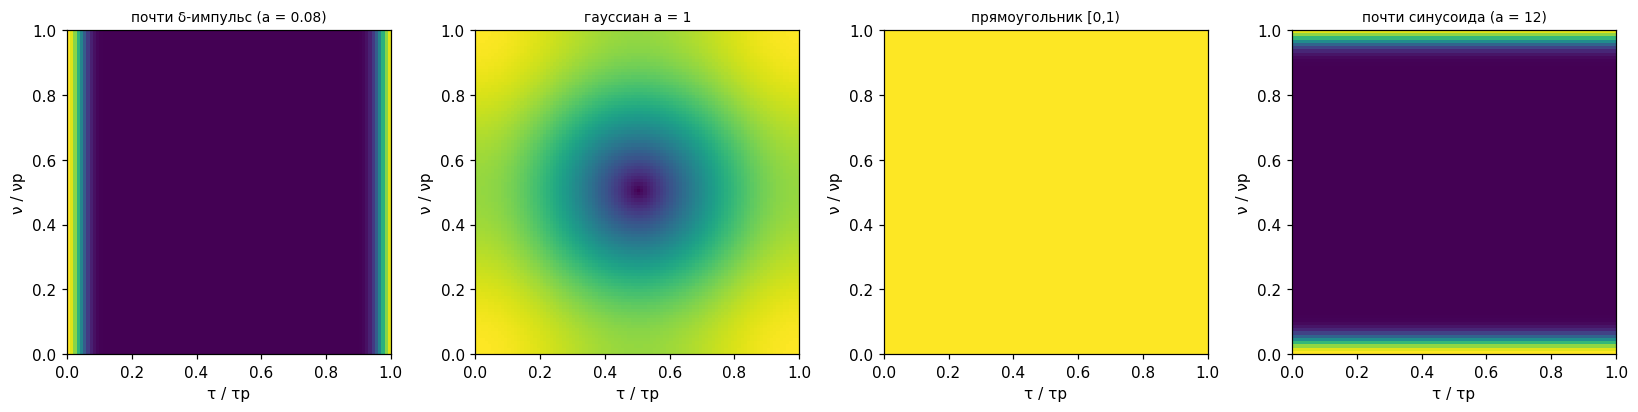

In [8]:
tau = np.arange(100) / 100; nu = np.arange(100) / 100            # сетка включает точку 0.5
cases = [("почти δ-импульс (a = 0.08)", lambda t: gauss(t, 0.08), 40),
         ("гауссиан a = 1", gauss, 40),
         ("прямоугольник [0,1)", rect, 40),
         ("почти синусоида (a = 12)", lambda t: gauss(t, 12), 120)]
fig, ax = plt.subplots(1, 4, figsize=(15, 3.9))
print(f"{'сигнал':<44}{'min|Z|':>10}{'max|Z|':>10}")
for a_, (name, f, K) in zip(ax, cases):
    Zc = zak(f, tau, nu, K=K)
    im = show_dd(a_, Zc, (0, 1, 0, 1), name)
    a_.title.set_fontsize(9)
    print(f"{name:<44}{np.abs(Zc).min():>10.2e}{np.abs(Zc).max():>10.2e}")
plt.tight_layout(); plt.show()

## 7. Нуль в точке $(\tfrac12,\tfrac12)$
**Утверждение A (симметрия).** Если импульс **чётный**, $x(-t)=x(t)$, то $Z_x(\tfrac12,\tfrac12)=0$.

**Утверждение B (общее).** Если $x$ непрерывен и убывает быстрее $1/\lvert t\rvert^{1+\varepsilon}$ (чтобы ряд для $Z$ сходился равномерно и $Z$ был непрерывной функцией), то у $Z_x$ **есть нуль в каждой ячейке**. Где именно — зависит от сигнала; у чётного он в $(\tfrac12,\tfrac12)$.

Ниже три независимых объяснения, от самого простого к самому общему.

### 7а. Знакопеременная сумма: слагаемые гасят друг друга парами
Подставим $\tau=\nu=\tfrac12$ в определение: $e^{-j\pi k}=(-1)^k$, и
$$Z(\tfrac12,\tfrac12)=\sum_k(-1)^k\,x(\tfrac12+k)=\dots-x(-\tfrac32)+x(-\tfrac12)\;-\;x(\tfrac12)+x(\tfrac32)-\dots$$
Для чётного $x$ значения симметричны: $x(\tfrac12+k)=x(-\tfrac12-k)$. Сопоставим слагаемое $k$ со слагаемым $k'=-1-k$: их модули равны, а знаки $(-1)^k$ и $(-1)^{-1-k}=-(-1)^k$ **противоположны**. Вся сумма разбилась на пары вида $a-a=0$. Это и есть нуль, причём без единой оговорки про форму импульса: гауссиан, косинус-приподнятый, любая чётная функция. Ниже — таблица слагаемых (для наглядности взят более широкий гауссиан, $a=2$) и столбики: слагаемые $k$ и $-1-k$ одного цвета равны по модулю и противоположны по знаку.

А если импульс сдвинуть на $a$ по времени и промодулировать на $b$ по частоте, $x_s(t)=x(t-a)e^{j2\pi bt}$? Прямой подсчёт даёт $Z_{x_s}(\tau,\nu)=e^{j2\pi b\tau}Z_x(\tau-a,\nu-b)$, то есть **весь рельеф сдвигается**, и нуль переезжает в $(\tfrac12+a,\ \tfrac12+b)$. На правом графике это проверено численно: $a=0.2$, $b=0.1$.

  k  t = ½ + k      x(t)  (−1)^k   слагаемое
 -4       -3.5   0.00007       1     0.00007
 -3       -2.5   0.00738      -1    -0.00738
 -2       -1.5   0.17082       1     0.17082
 -1       -0.5   0.82172      -1    -0.82172
  0        0.5   0.82172       1     0.82172
  1        1.5   0.17082      -1    -0.17082
  2        2.5   0.00738       1     0.00738
  3        3.5   0.00007      -1    -0.00007
сумма = Z(½, ½) = 0.00e+00
|Z(½,½)| для сдвинутого сигнала = 0.589
ноль найден в (τ, ν) = (0.700000, 0.600000),  предсказание (½ + a, ½ + b) = (0.700000, 0.600000),  |Z| = 5.6e-17


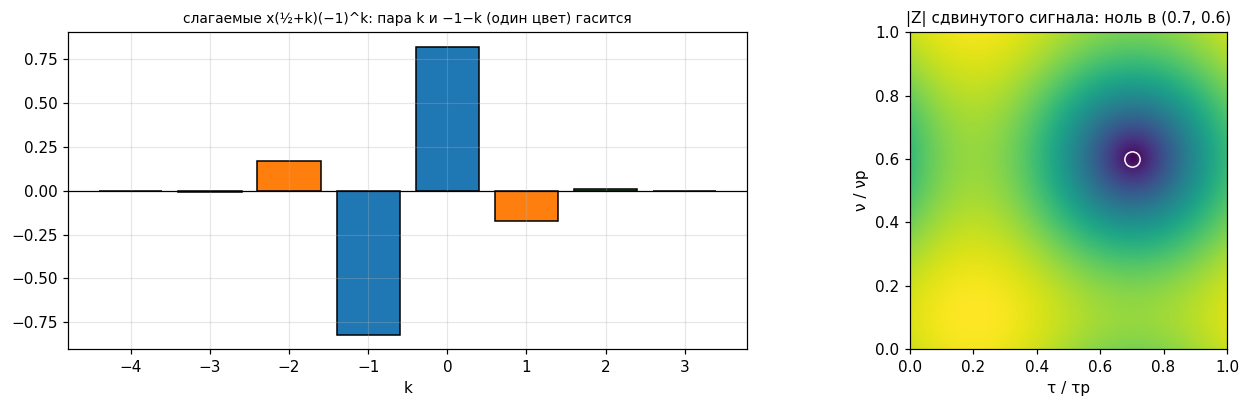

In [9]:
k = np.arange(-4, 4)
g2 = lambda t: gauss(t, 2.0)                                   # шире, чтобы слагаемых было видно больше
terms = g2(0.5 + k) * (-1.0) ** k
print(f"{'k':>3}{'t = ½ + k':>11}{'x(t)':>10}{'(−1)^k':>8}{'слагаемое':>12}")
for kk, tm in zip(k, terms): print(f"{kk:>3}{0.5 + kk:>11.1f}{g2(0.5 + kk):>10.5f}{(-1.0) ** kk:>8.0f}{tm:>12.5f}")
print(f"сумма = Z(½, ½) = {terms.sum():.2e}")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
pair = np.where(k >= 0, k, -1 - k)                              # пара (k, −1−k) — один цвет
ax[0].bar(k, terms, color=[f"C{p}" for p in pair], edgecolor="k")
ax[0].axhline(0, color="k", lw=0.8)
ax[0].set_xlabel("k"); ax[0].set_title("слагаемые x(½+k)(−1)^k: пара k и −1−k (один цвет) гасится", fontsize=9)

# сдвинутый и промодулированный гауссиан: ноль уходит из (½, ½)
a_s, b_s = 0.2, 0.1
xs_ = lambda t: gauss(np.asarray(t) - a_s) * np.exp(2j * np.pi * b_s * np.asarray(t))
tt_ = np.arange(200) / 200; Zs = zak(xs_, tt_, tt_)
i, j = np.unravel_index(np.argmin(np.abs(Zs)), Zs.shape)
res = minimize(lambda p: abs(zak_pairs(xs_, p[0], p[1])[0]) ** 2, [tt_[i], tt_[j]], method="Nelder-Mead", options=dict(xatol=1e-10, fatol=1e-30))
print(f"|Z(½,½)| для сдвинутого сигнала = {abs(zak_pairs(xs_, 0.5, 0.5)[0]):.3f}")
print(f"ноль найден в (τ, ν) = ({res.x[0]:.6f}, {res.x[1]:.6f}),  предсказание (½ + a, ½ + b) = ({0.5 + a_s:.6f}, {0.5 + b_s:.6f}),  |Z| = {np.sqrt(res.fun):.1e}")
show_dd(ax[1], Zs, (0, 1, 0, 1), "|Z| сдвинутого сигнала: ноль в (0.7, 0.6)")
ax[1].plot(*res.x, "wo", mfc="none", ms=10)
plt.tight_layout(); plt.show()

### 7б. Симметрия + скрутка: почему именно $(\tfrac12,\tfrac12)$ и не другие точки
Отражение $t\mapsto-t$ действует на плоскость как $(\tau,\nu)\mapsto(-\tau,-\nu)$: для чётного $x$ получаем $Z(-\tau,-\nu)=Z(\tau,\nu)$ (проверьте подстановкой $k\to-k$). Неподвижные точки этого отражения *по модулю решётки* — четыре: $(0,0),\ (\tfrac12,0),\ (0,\tfrac12),\ (\tfrac12,\tfrac12)$. Проверим, что требует квазипериодичность в каждой из них. В $(\tfrac12,\tfrac12)$:
$$Z(-\tfrac12,-\tfrac12)\overset{\text{период по }\nu}{=}Z(-\tfrac12,\tfrac12)\overset{\text{скрутка, }n=-1}{=}e^{-j2\pi\cdot\frac12}Z(\tfrac12,\tfrac12)=-Z(\tfrac12,\tfrac12).$$
А симметрия говорит, что левая часть равна $+Z(\tfrac12,\tfrac12)$. Единственное число, равное своему отрицанию, — нуль. В остальных трёх неподвижных точках скрутка $e^{j2\pi n\nu}$ равна $+1$ (там либо $\nu=0$, либо сдвиг $n=0$), противоречия нет, и значения ненулевые (последняя печать). **Нуль возникает ровно там, где скрутка даёт $-1$**: это вклад «пол-оборота фазы» из раздела 3.

In [10]:
P = rng.uniform(-1.5, 1.5, (2000, 2)); tt, nn = P[:, 0], P[:, 1]
e1 = np.max(np.abs(zak_pairs(g, -tt, -nn) - zak_pairs(g, tt, nn)))
print(f"чётный сигнал:  max|Z(−τ,−ν) − Z(τ,ν)| = {e1:.1e}")
e2 = np.max(np.abs(zak_pairs(g, tt - 1, nn) - np.exp(-2j * np.pi * nn) * zak_pairs(g, tt, nn)))
print(f"квазипериодичность:  max|Z(τ−1,ν) − e^(−j2πν)·Z(τ,ν)| = {e2:.1e}")
z = zak_pairs(g, [0.5, -0.5, -0.5], [0.5, 0.5, -0.5])
print("Z(½,½), Z(−½,½), Z(−½,−½) =", np.round(z, 12), "  → второй = −первому (скрутка e^{−jπ} = −1), третий = второму (период по ν)")

print("\nчетыре неподвижные точки отражения (τ, ν) → (−τ, −ν) по модулю решётки:")
for p in ((0, 0), (0.5, 0), (0, 0.5), (0.5, 0.5)):
    print(f"  (τ, ν) = {p}:  Z = {zak_pairs(g, p[0], p[1])[0]:+.5f}")

чётный сигнал:  max|Z(−τ,−ν) − Z(τ,ν)| = 2.5e-16
квазипериодичность:  max|Z(τ−1,ν) − e^(−j2πν)·Z(τ,ν)| = 7.9e-16
Z(½,½), Z(−½,½), Z(−½,−½) = [ 0.+0.j -0.-0.j -0.+0.j]   → второй = −первому (скрутка e^{−jπ} = −1), третий = второму (период по ν)

четыре неподвижные точки отражения (τ, ν) → (−τ, −ν) по модулю решётки:
  (τ, ν) = (0, 0):  Z = +1.08643+0.00000j
  (τ, ν) = (0.5, 0):  Z = +0.91358+0.00000j
  (τ, ν) = (0, 0.5):  Z = +0.91358+0.00000j
  (τ, ν) = (0.5, 0.5):  Z = +0.00000+0.00000j


### 7в. Топология: фаза обязана «закрутиться», а значит где-то есть вихрь
Для несимметричного сигнала предыдущий аргумент не работает, но нуль всё равно есть. Допустим, $Z$ непрерывна и **нигде не равна нулю** в $[0,1]^2$. Тогда у неё определена непрерывная фаза, и можно измерить, на сколько она изменилась при обходе границы квадрата. Обойдём границу (снизу, справа, сверху, слева) и сложим набеги фазы, пользуясь квазипериодичностью:
- нижняя и верхняя стороны: $Z(\tau,1)=Z(\tau,0)$, а идём по ним в противоположных направлениях, поэтому набеги фазы взаимно сокращаются;
- правая и левая стороны: $Z(1,\nu)=e^{j2\pi\nu}Z(0,\nu)$. По левой идём вниз (набег $-\Delta$), по правой вверх: $+\Delta$ от самой $Z(0,\nu)$ плюс набег множителя $e^{j2\pi\nu}$ при $\nu$ от 0 до 1, то есть $+2\pi$. Собственные набеги сокращаются, остаётся скрутка.

Сумма: **$+2\pi$, то есть фаза делает ровно один оборот по границе**. Но если внутри квадрата нулей нет, фазу можно непрерывно «стянуть» в точку, и оборот по замкнутому контуру обязан быть **0**. Противоречие. Значит, внутри есть нуль, и **оборот фазы вокруг него (индекс) равен $+1$**: нуль — это вихрь, около которого $Z\approx\alpha\,\delta\tau+\beta\,\delta\nu$ (линейно, поэтому $\lvert Z\rvert$ растёт как расстояние, «конус»). Слово «нигде не ноль» нигде не использовало симметрию, так что это же верно для любого непрерывного сигнала.

Численно: считаем число оборотов фазы по границе единичного квадрата и по малой окружности вокруг нуля для гауссиана, сдвинутого сигнала и восьми случайных гладких сигналов. Всегда $+1$. У прямоугольника нуля нет, потому что нарушено условие: $Z$ **разрывна** на линии $\tau=1$, «вихрь» там размазан по скачку.

гауссиан a=1:  winding = +1.0000   вокруг (½,½) радиусом 0.1: +1.0000
гауссиан a=0.5: winding = +1.0000


сдвинутый и промодулированный: winding = +1.0000
случайные гладкие комплексные сигналы: 

+1.000  +1.000  +1.000  +1.000  +1.000  +1.000  +1.000  +1.000


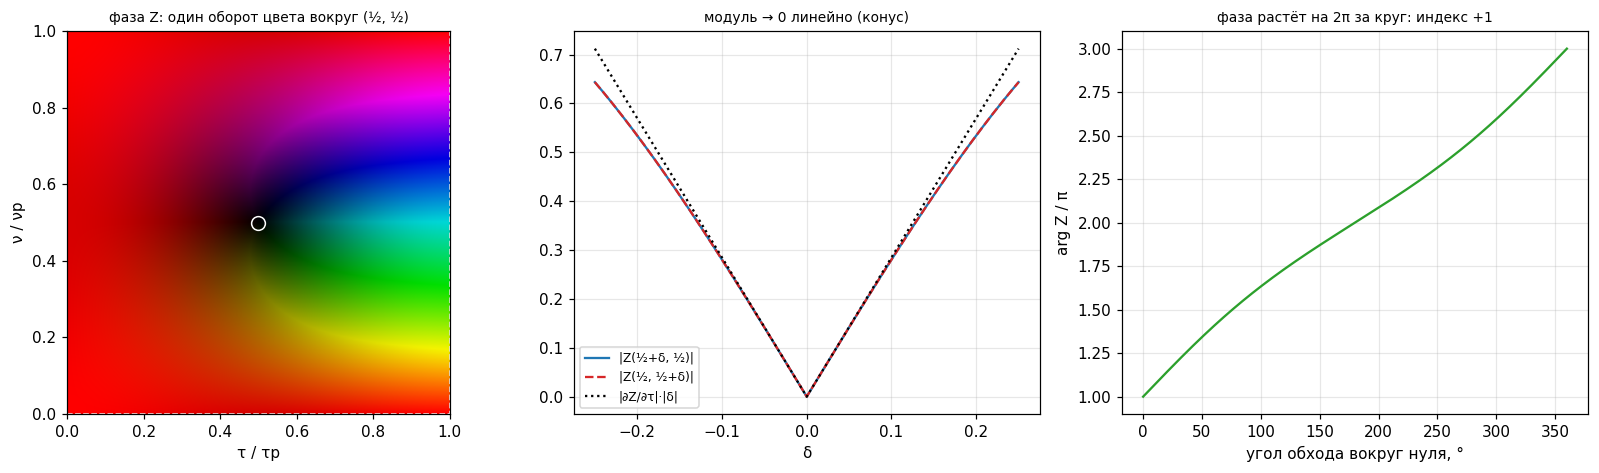

∂Z/∂τ = -2.8487+0.0000j,  ∂Z/∂ν = 0.0000-2.8487j   → вблизи нуля Z ≈ α·δτ + β·δν; здесь β = jα — круговой вихрь


In [11]:
def winding(x, centre=None, radius=None, n=4000):
    """сколько оборотов делает фаза Z вдоль контура (против часовой стрелки): единичный квадрат [0,1]² или окружность"""
    s = np.linspace(0, 1, n, endpoint=False)
    if centre is None:
        tt = np.concatenate([s, np.ones(n), 1 - s, np.zeros(n)]); nn = np.concatenate([np.zeros(n), s, np.ones(n), 1 - s])
    else:
        ang = 2 * np.pi * np.linspace(0, 1, 4 * n + 1)
        tt = centre[0] + radius * np.cos(ang); nn = centre[1] + radius * np.sin(ang)
    Zp = zak_pairs(x, tt, nn)
    if centre is None: Zp = np.append(Zp, Zp[0])
    return np.sum(np.angle(Zp[1:] / Zp[:-1])) / (2 * np.pi)

print(f"гауссиан a=1:  winding = {winding(g):+.4f}   вокруг (½,½) радиусом 0.1: {winding(g, (0.5, 0.5), 0.1):+.4f}")
print(f"гауссиан a=0.5: winding = {winding(lambda t: gauss(t, 0.5)):+.4f}")
print(f"сдвинутый и промодулированный: winding = {winding(xs_):+.4f}")
print("случайные гладкие комплексные сигналы:", end=" ")
print("  ".join(f"{winding(random_signal(rng, 4)):+.3f}" for _ in range(8)))

# картинка: фаза и поперечные сечения модуля через ноль
tau = np.arange(300) / 300; Zg = zak(g, tau, tau)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
show_dd(ax[0], Zg, (0, 1, 0, 1), "фаза Z: один оборот цвета вокруг (½, ½)", phase=True)
ax[0].plot([0, 1, 1, 0, 0], [0, 0, 1, 1, 0], "w--", lw=1); ax[0].plot(0.5, 0.5, "wo", mfc="none", ms=9)
ax[0].title.set_fontsize(9)
d = np.linspace(-0.25, 0.25, 201)
cut_t = np.abs(zak(g, 0.5 + d, [0.5])[:, 0]); cut_n = np.abs(zak(g, [0.5], 0.5 + d)[0])
h = 1e-5
dZt = (zak_pairs(g, 0.5 + h, 0.5)[0] - zak_pairs(g, 0.5 - h, 0.5)[0]) / (2 * h)
dZn = (zak_pairs(g, 0.5, 0.5 + h)[0] - zak_pairs(g, 0.5, 0.5 - h)[0]) / (2 * h)
ax[1].plot(d, cut_t, "C0", label="|Z(½+δ, ½)|"); ax[1].plot(d, cut_n, "C3--", label="|Z(½, ½+δ)|")
ax[1].plot(d, np.abs(dZt) * np.abs(d), "k:", label="|∂Z/∂τ|·|δ|")
ax[1].set_xlabel("δ"); ax[1].legend(fontsize=8); ax[1].set_title("модуль → 0 линейно (конус)", fontsize=9)
ang = np.linspace(0, 2 * np.pi, 400); r = 0.08
Zc = zak_pairs(g, 0.5 + r * np.cos(ang), 0.5 + r * np.sin(ang))
ax[2].plot(np.degrees(ang), np.unwrap(np.angle(Zc)) / np.pi, "C2"); ax[2].set_xlabel("угол обхода вокруг нуля, °"); ax[2].set_ylabel("arg Z / π")
ax[2].set_title("фаза растёт на 2π за круг: индекс +1", fontsize=9)
plt.tight_layout(); plt.show()
print(f"∂Z/∂τ = {dZt:.4f},  ∂Z/∂ν = {dZn:.4f}   → вблизи нуля Z ≈ α·δτ + β·δν; здесь β = jα — круговой вихрь")

## 8. Следствия: ортогональность, матрица Грама, Балиан–Лоу
**Как Зак действует на решётку импульсов.** Возьмём импульс $g$ и его копии $g_{m,n}(t)=g(t-m)\,e^{j2\pi nt}$ — сдвиги на целые периоды по задержке и целые $\nu_p$ по доплеру. Именно такую решётку образуют символы Zak-OTFS (пульсоны). Подстановка в определение (для целых $m,n$ множитель $e^{j2\pi nk}=1$) даёт
$$Z_{g_{m,n}}(\tau,\nu)=e^{\,j2\pi(n\tau-m\nu)}\,Z_g(\tau,\nu).$$
Сдвиг и модуляция **превращаются в умножение на гармонику**: $g_{m,n}\mapsto e^{j2\pi(n\tau-m\nu)}Z_g$. А гармоники $e^{j2\pi(n\tau-m\nu)}$ образуют ортонормальный базис $L^2([0,1)^2)$. По унитарности скалярное произведение копий:
$$\langle g,g_{m,n}\rangle=\iint_{[0,1)^2}\lvert Z_g(\tau,\nu)\rvert^2\,e^{\,j2\pi(n\tau-m\nu)}\,d\tau\,d\nu,$$
то есть **матрица Грама решётки — коэффициенты Фурье функции $\lvert Z_g\rvert^2$**. Отсюда три вывода:
1. решётка $\{g_{m,n}\}$ **ортонормальна** $\Leftrightarrow$ $\lvert Z_g\rvert^2\equiv1$ (все коэффициенты Фурье, кроме нулевого, равны нулю);
2. собственные числа оператора Грама — значения $\lvert Z_g\rvert^2$ по плоскости; решётка — базис Рисса, только если $0<\min\lvert Z_g\rvert^2\le\max\lvert Z_g\rvert^2<\infty$;
3. **если $Z_g$ непрерывна, то по разделу 7 у неё есть нуль, $\min\lvert Z_g\rvert=0$, и решётка не может быть даже базисом Рисса** — ни ортонормальным, ни просто устойчивым. Это **теорема Балиана–Лоу** в её «зачатке»: *импульс не может быть одновременно хорошо локализован во времени и в частоте (гладкий и быстро убывающий), и давать ортонормальную решётку критической плотности $\tau_p\nu_p=1$*.

Проверим. Печать №1: правило $Z_{g_{m,n}}$. Печать №2: матрица Грама гауссиана, посчитанная интегралом во времени и через коэффициенты Фурье $\lvert Z\rvert^2$ — совпадение. Перекрытие с четырьмя соседями равно $e^{-\pi/2}\approx0.21$.

In [12]:
# правило: сдвиг на m и модуляция на n умножают Z на e^{j2π(nτ − mν)}
m_, n_ = 2, -3
gmn = lambda t: gauss(np.asarray(t) - m_) * np.exp(2j * np.pi * n_ * np.asarray(t))
P = rng.uniform(-1, 1, (500, 2)); tt, nn = P[:, 0], P[:, 1]
print(f"max|Z_(m,n)(τ,ν) − e^(j2π(nτ − mν))·Z_g(τ,ν)| = {np.max(np.abs(zak_pairs(gmn, tt, nn) - np.exp(2j * np.pi * (n_ * tt - m_ * nn)) * zak_pairs(g, tt, nn))):.1e}")

# матрица Грама соседей по решётке: во времени и через Фурье-коэффициенты |Z|²
dt = 0.002; tg = np.arange(-12, 12, dt)
tau = np.arange(200) / 200; nu = np.arange(200) / 200
W = np.abs(zak(g, tau, nu)) ** 2
Tm, Nm = np.meshgrid(tau, nu, indexing="ij")
E = np.sum(g(tg) ** 2) * dt
G_time = np.zeros((3, 3), complex); G_zak = np.zeros((3, 3), complex)
for i, m in enumerate((-1, 0, 1)):
    for j, n in enumerate((-1, 0, 1)):
        G_time[i, j] = np.sum(g(tg) * g(tg - m) * np.exp(2j * np.pi * n * tg)) * dt / E
        G_zak[i, j] = np.mean(W * np.exp(2j * np.pi * (n * Tm - m * Nm))) / np.mean(W)
np.set_printoptions(precision=4, suppress=True)
print("⟨g, g_(m,n)⟩/‖g‖² во времени (строки m = −1,0,1; столбцы n = −1,0,1):\n", G_time.real)
print("через Фурье-коэффициенты |Z|²:\n", G_zak.real)
print(f"max|Δ| = {np.max(np.abs(G_time - G_zak)):.1e};   e^(−π/2) = {np.exp(-np.pi / 2):.4f}  — перекрытие с четырьмя соседями по решётке")

max|Z_(m,n)(τ,ν) − e^(j2π(nτ − mν))·Z_g(τ,ν)| = 1.2e-14
⟨g, g_(m,n)⟩/‖g‖² во времени (строки m = −1,0,1; столбцы n = −1,0,1):
 [[-0.0432  0.2079 -0.0432]
 [ 0.2079  1.      0.2079]
 [-0.0432  0.2079 -0.0432]]
через Фурье-коэффициенты |Z|²:
 [[-0.0432  0.2079 -0.0432]
 [ 0.2079  1.      0.2079]
 [-0.0432  0.2079 -0.0432]]
max|Δ| = 2.2e-16;   e^(−π/2) = 0.2079  — перекрытие с четырьмя соседями по решётке


Спектр оператора Грама для трёх импульсов. Прямоугольник во времени и sinc (прямоугольник в частоте) — **идеальны**: $\lvert Z\rvert^2\equiv1$, решётка ортонормальна. Но каждый из них плохо локализован с одной из сторон (прямоугольник — хвосты спектра $\propto1/f$, sinc — хвосты во времени $\propto1/t$), и $Z$ у них разрывна, поэтому нуля нет, как и положено теореме. Гауссиан локализован с обеих сторон, но его $\lvert Z\rvert^2$ проходит через нуль: у оператора Грама есть сколь угодно малые собственные числа, и любой приёмник, который решает систему с этой матрицей (ZF, LMMSE), усиливает шум именно в направлении этого нуля.

импульс                                         min |Z|²    max |Z|²   = собственные числа матрицы Грама
гауссиан                                           0.000       1.669
прямоугольник во времени                           1.000       1.000
sinc (прямоугольник в частоте)                     1.000       1.000


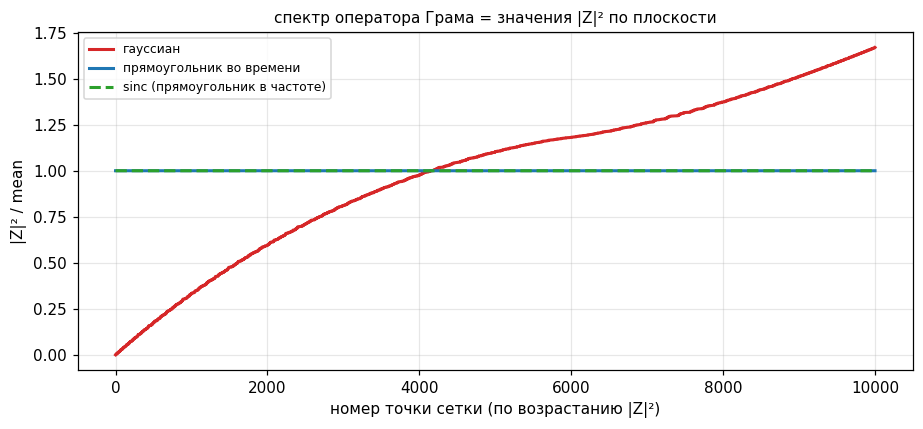

In [13]:
tau = np.arange(100) / 100; nu = np.arange(100) / 100
sinc_X = lambda f: ((f >= -0.5) & (f < 0.5)).astype(float)       # спектр sinc — прямоугольник
sets = {"гауссиан": np.abs(zak(g, tau, nu)) ** 2,
        "прямоугольник во времени": np.abs(zak(rect, tau, nu)) ** 2,
        "sinc (прямоугольник в частоте)": np.abs(zak_from_spectrum(sinc_X, tau, nu)) ** 2}
fig, ax = plt.subplots(figsize=(8.5, 4))
print(f"{'импульс':<44}{'min |Z|²':>12}{'max |Z|²':>12}   = собственные числа матрицы Грама")
for (name, w), c in zip(sets.items(), ("C3", "C0", "C2")):
    w = w / w.mean()
    ax.plot(np.sort(w.ravel()), c, lw=2, ls="--" if "sinc" in name else "-", label=name)
    print(f"{name:<44}{w.min():>12.3f}{w.max():>12.3f}")
ax.set_xlabel("номер точки сетки (по возрастанию |Z|²)"); ax.set_ylabel("|Z|² / mean"); ax.legend(fontsize=8)
ax.set_title("спектр оператора Грама = значения |Z|² по плоскости", fontsize=10)
plt.tight_layout(); plt.show()

**Можно ли «починить» гауссиан?** Да, но ценой хвостов. Раз Грам — это $\lvert Z\rvert^2$, то разделим $Z$ на $\lvert Z\rvert$: $g_\perp=\mathrm{Zak}^{-1}[\,Z_g/\lvert Z_g\rvert\,]$. У нового импульса $\lvert Z_{g_\perp}\rvert\equiv1$, решётка ортонормальна. Но $Z_g/\lvert Z_g\rvert$ в точке нуля **не определена** (вихрь, фаза принимает все значения), то есть разрывна — а разрывность $Z$ по обратному преобразованию Фурье в $\nu$ даёт **степенной хвост** $\sim1/\lvert t\rvert$ вместо $e^{-\pi t^2}$. На правом графике показаны огибающие: у $g_\perp$ при больших $k$ видно $\approx(0.3\text{–}0.4)/k$, у исходного гауссиана — обрыв ниже $10^{-16}$ уже при $k\approx4$. Это Балиан–Лоу на деле: ортогональность обменяна на локализацию.

Практический вывод для Zak-OTFS: нельзя получить всё сразу — ортогональные символы, быстро убывающий импульс (малая внеполосная эмиссия, малая память канала) и критическую плотность $\tau_p\nu_p=1$. Реальные импульсы (гаусс-sinc, RRC) — компромисс: допускают неглубокий провал $\lvert Z\rvert$ у $(\tfrac12,\tfrac12)$ вместо нуля или скачка; в OFDM аналогичный выход — циклический префикс, то есть $\tau_p\nu_p>1$ (решётка реже критической, ограничение Балиана–Лоу исчезает).

‖g⊥‖² = 1.0000  (единичная норма: |U| = 1)


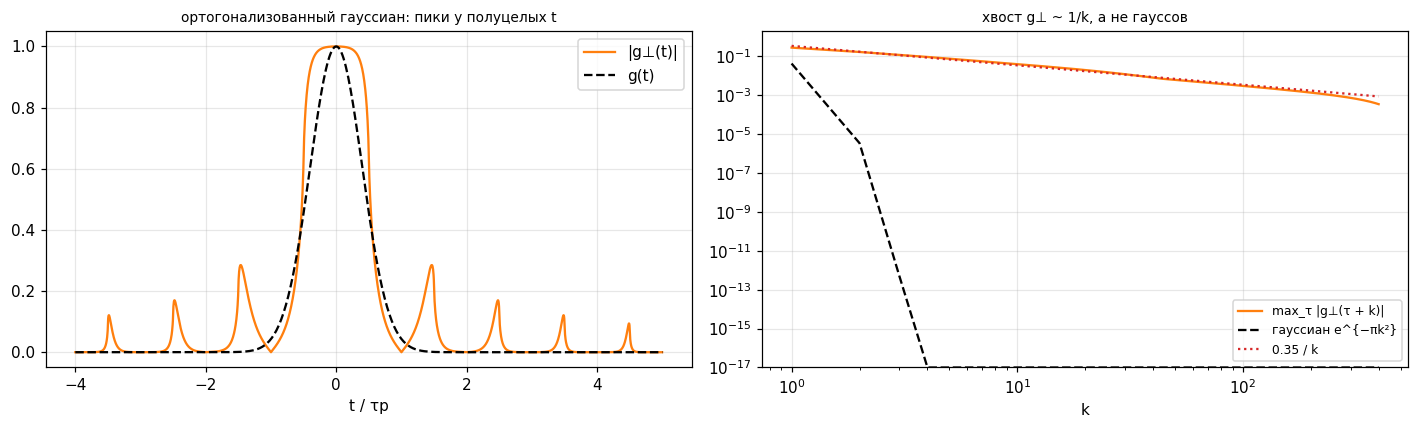

k·max|g⊥|: [0.376 0.394 0.407 0.358 0.312 0.3  ]  → примерно константа: хвост ∝ 1/k


In [14]:
# ортогонализация: g⊥ = Zак⁻¹[ Z/|Z| ]
Q, Nn = 256, 1024
tq = np.arange(Q) / Q; nq = np.arange(Nn) / Nn
Zq = zak(g, tq, nq, K=8)
Aq = np.abs(Zq); U = np.where(Aq > 1e-9, Zq / np.maximum(Aq, 1e-300), 0)       # |U| = 1 всюду, кроме одной точки
gperp = np.fft.ifft(U, axis=1)                                                  # gperp[iτ, k] = g⊥(τ + k)
print(f"‖g⊥‖² = {np.sum(np.abs(gperp) ** 2) / Q:.4f}  (единичная норма: |U| = 1)")
env = np.abs(gperp).max(axis=0)[1:400]
kk = np.arange(1, 400)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
tt = (tq[:, None] + np.arange(-4, 5)[None, :])
order = np.argsort(tt.ravel()); gp_t = np.array([gperp[i, k % Nn] for i in range(Q) for k in range(-4, 5)])
ax[0].plot(tt.ravel()[order], np.abs(gp_t)[order], "C1", label="|g⊥(t)|"); ax[0].plot(np.linspace(-4, 5, 500), gauss(np.linspace(-4, 5, 500)), "k--", label="g(t)")
ax[0].set_xlabel("t / τp"); ax[0].legend(); ax[0].set_title("ортогонализованный гауссиан: пики у полуцелых t", fontsize=9)
ax[1].loglog(kk, env, "C1", label="max_τ |g⊥(τ + k)|"); ax[1].loglog(kk, np.exp(-np.pi * kk ** 2) + 1e-17, "k--", label="гауссиан e^{−πk²}")
ax[1].loglog(kk, 0.35 / kk, "C3:", label="0.35 / k")
ax[1].set_ylim(1e-17, 2); ax[1].set_xlabel("k"); ax[1].legend(fontsize=8); ax[1].set_title("хвост g⊥ ~ 1/k, а не гауссов", fontsize=9)
plt.tight_layout(); plt.show()
print("k·max|g⊥|:", np.round(env[[3, 7, 15, 31, 63, 127]] * kk[[3, 7, 15, 31, 63, 127]], 3), " → примерно константа: хвост ∝ 1/k")

## 9. Дискретный вариант: зачем $M$ и $N$ чётные
Дискретное $Z[k,l]$ из `zak_sim` — это отсчёты $Z(\tau,\nu)$ в точках $\tau=k/M$, $\nu=l/N$. Сетка попадает в точку $(\tfrac12,\tfrac12)$, то есть $k=M/2$, $l=N/2$, **только если $M$ и $N$ чётные**. Тогда нуль виден в данных точно, до машинной точности ($\sim10^{-17}$), и строгое равенство «пары гасятся» работает на самих отсчётах: $\sum_n(-1)^n\,x[M/2+nM]$ с симметричным $x$. Для нечётных $M$ или $N$ сетка проскакивает мимо нуля и минимум $\lvert Z\rvert$ мал, но не равен нулю. Для реального кадра это родственная история: потеря 3–5 дБ гауссовых окон относительно rect при точном $H$ (раздел 5 `zak_sim`) — следствие того, что $\lvert Z\rvert\ne1$, то есть неортогональности гауссовых символов.

In [15]:
# дискретный вариант: Z[k, l] — это Z(τ, ν) в точках τ = k/M, ν = l/N
def dzt_gauss(M, N, a=1.0, K=30):
    n = np.arange(-K, K + 1)
    k = np.arange(M)
    xs = np.exp(-np.pi * ((k[:, None] + n[None, :] * M) / (a * M)) ** 2)         # отсчёты g(τ + n), τ = k/M
    return (xs @ np.exp(-2j * np.pi * np.outer(n, np.arange(N) / N))) / np.sqrt(N)  # Z[k, l]

for M_, N_ in ((8, 8), (16, 4), (64, 16), (7, 8), (8, 7), (7, 7)):
    Zd = dzt_gauss(M_, N_)
    kmin, lmin = np.unravel_index(np.argmin(np.abs(Zd)), Zd.shape)
    print(f"M = {M_:>2}, N = {N_:>2}:  min|Z[k,l]| = {np.abs(Zd).min():.2e}  в точке (k, l) = ({kmin}, {lmin})  → (τ, ν) = ({kmin / M_:.3f}, {lmin / N_:.3f})")

M =  8, N =  8:  min|Z[k,l]| = 2.12e-17  в точке (k, l) = (4, 4)  → (τ, ν) = (0.500, 0.500)
M = 16, N =  4:  min|Z[k,l]| = 3.00e-17  в точке (k, l) = (8, 2)  → (τ, ν) = (0.500, 0.500)
M = 64, N = 16:  min|Z[k,l]| = 1.50e-17  в точке (k, l) = (32, 8)  → (τ, ν) = (0.500, 0.500)
M =  7, N =  8:  min|Z[k,l]| = 7.14e-02  в точке (k, l) = (3, 4)  → (τ, ν) = (0.429, 0.500)
M =  8, N =  7:  min|Z[k,l]| = 7.63e-02  в точке (k, l) = (4, 4)  → (τ, ν) = (0.500, 0.571)
M =  7, N =  7:  min|Z[k,l]| = 1.07e-01  в точке (k, l) = (4, 4)  → (τ, ν) = (0.571, 0.571)


## Итоги
| Что | Формула / факт | Где проверено |
|---|---|---|
| Определение | $Z(\tau,\nu)=\sum_kx(\tau+k)e^{-j2\pi\nu k}$ = reshape + БПФ | раздел 1–2 |
| Квазипериодичность | $Z(\tau+n,\nu+m)=e^{j2\pi n\nu}Z(\tau,\nu)$ | раздел 3 |
| Обратное и Парсеваль | $x(t)=\int_0^1Z(t,\nu)d\nu$, $\int\lvert x\rvert^2=\iint\lvert Z\rvert^2$ | раздел 4 |
| Через спектр | $Z=e^{j2\pi\nu\tau}\sum_mX(\nu+m)e^{j2\pi m\tau}$ | раздел 5 |
| Нуль чётного импульса | $Z(\tfrac12,\tfrac12)=\sum(-1)^kx(\tfrac12+k)=0$ | раздел 7а, 7б |
| Нуль у любого гладкого | оборот фазы по границе ячейки $=+1$ $\Rightarrow$ вихрь внутри | раздел 7в |
| Решётка импульсов | Грам = коэффициенты Фурье $\lvert Z_g\rvert^2$; ортонормальность $\Leftrightarrow\lvert Z_g\rvert\equiv1$ | раздел 8 |
| Балиан–Лоу | гладкий + локализованный $\Rightarrow$ нуль $\Rightarrow$ нет ортонормальной решётки при $\tau_p\nu_p=1$ | раздел 8 |
| Цена ортогонализации | $g_\perp$ имеет хвост $\sim1/\lvert t\rvert$ | раздел 8 |

**Короткий ответ на «почему нуль в $(\tfrac12,\tfrac12)$»:** потому что при сдвиге на период Зак-плоскость получает фазу $e^{j2\pi\nu}$, которая при $\nu=\tfrac12$ равна $-1$; симметричный импульс требует, чтобы значение в этой точке совпадало со своим отражением, а скрутка требует, чтобы оно равнялось *минус* себе. Остаётся ноль. У несимметричного импульса нуль сдвигается, но не исчезает, потому что фаза на границе ячейки обязана сделать один оборот.

## Что покрутить
- в разделе 2 замените гауссиан на `rect` или `sinc_t`: исчезает ли нуль? (для `sinc_t` нужен `K` в сотни и всё равно плохая сходимость — это и есть хвост $1/t$)
- в разделе 6 поменяйте ширину $a$ у гауссиана на 0.5 и 2: положение нуля не меняется (импульс чётный), меняется форма «конуса» вокруг него
- в разделе 7а попробуйте несимметричный импульс, например $x(t)=e^{-\pi t^2}(1+0.5t)$: нуль уходит из $(\tfrac12,\tfrac12)$, `winding` по-прежнему $+1$
- в разделе 7в варьируйте число слагаемых в `random_signal(rng, n)`: суммарный индекс остаётся $+1$ (лишние нули, если появляются, приходят парами $+1/-1$)
- в разделе 8 замените `g` на `lambda t: gauss(t, 0.5)` или `gauss(t, 2)`: минимум $\lvert Z\rvert^2$ по-прежнему 0, меняется только форма кривой Грама
- в разделе 9 возьмите $M=64$, $N=16$ (как в `zak_sim`) и $M=63$: во втором случае нуль «спрятан» между отсчётами